### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Custom Function
from custom_function import *

In [5]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

### Loading

#### 1. Food Price

In [6]:
food_price = get_dataset('\\Datasets\\wfp_food_prices_mmr(Cleaned).csv')
food_price.drop(['latitude', 'longitude'],  axis='columns', inplace=True)
food_price.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [7]:
food_price = food_price[['date', 'usdprice']]
food_price['date'] = pd.to_datetime(food_price['date'])
food_price.columns = ['date', 'food_price']
food_price = food_price.set_index('date')
food_price = food_price.resample('AS-JAN').mean()
food_price.head()

,food_price
date,
2008-01-01,0.563348
2009-01-01,0.452433
2010-01-01,0.505708
2011-01-01,0.546463
2012-01-01,0.467904


#### 2. Food imports Price Dataset

In [8]:
temp_GDP = get_dataset('\\Datasets\\GDP_growth_percentage.csv')
temp_GDP.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,Aruba,ABW,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,3.446055,-1.369863,4.198232,0.300000,5.700001,2.100000,1.999999,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,4.014183,1.972652,4.308370,3.986754,2.925591,2.019391,2.542298,2.475272,2.077898,-2.939186
2,Afghanistan,AFG,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,0.426355,12.752287,5.600745,2.724543,1.451315,2.260314,2.647003,1.189228,3.911603,-2.351101
3,Africa Western and Central,AFW,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,1.848719,3.770212,7.272501,5.396356,4.049794,...,4.848351,5.142964,6.104241,5.927350,2.745937,0.127595,2.318042,2.952230,3.190336,-0.884981
4,Angola,AGO,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,3.471976,8.542188,4.954545,4.822628,0.943572,-2.580050,-0.147213,-2.003630,-0.624644,-5.399987


In [9]:
temp_GDP = temp_GDP[temp_GDP['Country Code'] == 'MMR']
temp_GDP

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
160,Myanmar,MMR,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,NaN,2.283469,8.810824,3.12561,2.147489,...,7.520057,6.485754,7.898669,8.199664,3.277279,10.507781,5.750064,6.404977,6.75046,3.173774


In [10]:
date = temp_GDP.columns
date = date[4:]
date

Index(['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020'],
      dtype='object')

In [11]:
date.shape

(61,)

In [12]:
GDP_percent = temp_GDP.copy()
GDP_percent = GDP_percent[date]
GDP_percent = GDP_percent.values
GDP_percent

array([[        nan,         nan,  2.28346888,  8.81082448,  3.12560964,
         2.14748864,  2.52599563, -5.37517435,  2.79249847,  7.42624378,
         4.14919875,  4.54433015,  3.26576416,  0.71337895,  2.17177782,
         4.73206671,  5.13615843,  6.01445149,  6.2432241 ,  5.83877189,
         6.60459872,  7.11693311,  5.96823659,  4.98095692,  4.66772854,
         3.86681055,  0.8693605 , -2.52365544, -7.6039605 , -4.28134264,
         3.24814801,  1.0590777 ,  4.48833585,  7.76673826,  6.7797676 ,
         7.2034554 ,  6.68690034,  6.03480423,  5.76184722,  8.47803412,
        12.41819164, 12.46773004, 11.70304562, 12.98632489, 13.69528734,
        13.56694201, 13.30686931, 12.50048629, 11.07426765, 10.4098444 ,
        10.06928609,  7.52005723,  6.485754  ,  7.89866948,  8.19966375,
         3.27727942, 10.50778078,  5.7500645 ,  6.40497732,  6.75046015,
         3.1737744 ]])

In [13]:
date = pd.to_datetime(date, format='%Y')

In [14]:
GDP_percent = GDP_percent[0]
GDP_percent.shape

(61,)

In [15]:
GDP = pd.DataFrame()
GDP['GDP_percent'] = GDP_percent
GDP

,GDP_percent
0,NaN
1,NaN
2,2.283469
3,8.810824
4,3.125610
...,...
56,10.507781
57,5.750064
58,6.404977
59,6.750460


##### Filling data with linear interpolation

In [16]:
GDP = GDP.interpolate(method='linear')
GDP

,GDP_percent
0,NaN
1,NaN
2,2.283469
3,8.810824
4,3.125610
...,...
56,10.507781
57,5.750064
58,6.404977
59,6.750460


In [17]:
GDP['date']=date
GDP = GDP.set_index('date')
GDP.columns=['GDP_percent']
GDP.head()

,GDP_percent
date,
1960-01-01,NaN
1961-01-01,NaN
1962-01-01,2.283469
1963-01-01,8.810824
1964-01-01,3.125610


In [18]:
GDP = GDP.dropna()
GDP.head()

,GDP_percent
date,
1962-01-01,2.283469
1963-01-01,8.810824
1964-01-01,3.125610
1965-01-01,2.147489
1966-01-01,2.525996


### Merge Food import and Food Price

In [19]:
food_price_GDP= food_price.join(GDP, how='inner')
food_price_GDP

,food_price,GDP_percent
date,,
2008-01-01,0.563348,11.074268
2009-01-01,0.452433,10.409844
2010-01-01,0.505708,10.069286
2011-01-01,0.546463,7.520057
2012-01-01,0.467904,6.485754
2013-01-01,0.513739,7.898669
2014-01-01,0.918071,8.199664
2015-01-01,1.059368,3.277279
2016-01-01,1.182692,10.507781


### Correlation

In [20]:
correlation=food_price_GDP['food_price'].corr(food_price_GDP['GDP_percent'])
correlation

-0.3160677208251949

### Make scatter plot

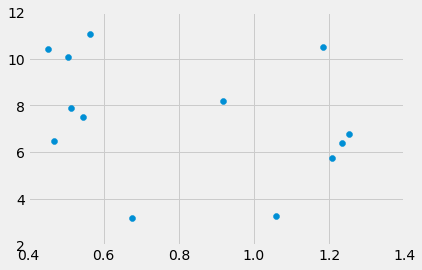

In [21]:
plt.scatter(food_price_GDP['food_price'],food_price_GDP['GDP_percent'])
plt.show()

### Normalization

In [22]:
date = food_price_GDP.index

In [23]:
scaler = MinMaxScaler()

In [24]:
food_price_GDP = scaler.fit_transform(food_price_GDP)
food_price_GDP = pd.DataFrame(food_price_GDP)
food_price_GDP['date'] = date
food_price_GDP.set_index('date', inplace=True)
food_price_GDP.columns = ['food_price', 'GDP_percent']
food_price_GDP.head()

,food_price,GDP_percent
date,,
2008-01-01,0.138512,1.000000
2009-01-01,0.000000,0.915901
2010-01-01,0.066530,0.872795
2011-01-01,0.117426,0.550128
2012-01-01,0.019321,0.419212


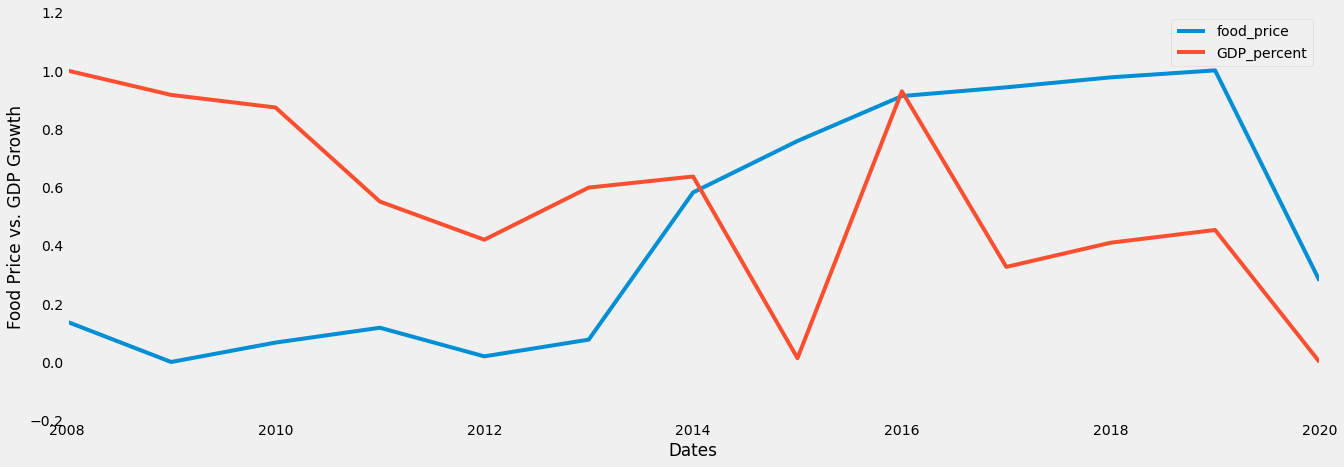

In [25]:
line_ax = food_price_GDP.plot(kind='line', figsize=(20, 7))
line_ax.set_ylabel('Food Price vs. GDP Growth')
line_ax.set_xlabel('Dates')
line_ax.grid()

<span style="color:red">There is nearly no relation between Food Price and GDP Growth Percentage. But it is negative relation</span>